In [246]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.preprocessing




In [247]:
df=pd.read_csv("/content/Automobile_data (1).csv")

In [248]:
df.head()

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,?,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450


In [249]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   body-style         205 non-null    object 
 5   drive-wheels       205 non-null    object 
 6   engine-location    205 non-null    object 
 7   width              205 non-null    float64
 8   height             205 non-null    float64
 9   engine-type        205 non-null    object 
 10  engine-size        205 non-null    int64  
 11  horsepower         205 non-null    object 
 12  city-mpg           205 non-null    int64  
 13  highway-mpg        205 non-null    int64  
 14  price              205 non-null    int64  
dtypes: float64(2), int64(5), object(8)
memory usage: 24.2+ KB


In [250]:
df.describe()

,symboling,width,height,engine-size,city-mpg,highway-mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,65.907805,53.724878,126.907317,25.219512,30.751220,13227.478049
std,1.245307,2.145204,2.443522,41.642693,6.542142,6.886443,7902.651615
min,-2.000000,60.300000,47.800000,61.000000,13.000000,16.000000,5118.000000
25%,0.000000,64.100000,52.000000,97.000000,19.000000,25.000000,7788.000000
50%,1.000000,65.500000,54.100000,120.000000,24.000000,30.000000,10345.000000
75%,2.000000,66.900000,55.500000,141.000000,30.000000,34.000000,16500.000000
max,3.000000,72.300000,59.800000,326.000000,49.000000,54.000000,45400.000000


In [251]:
df.columns

Index(['symboling', 'normalized-losses', 'make', 'fuel-type', 'body-style',
       'drive-wheels', 'engine-location', 'width', 'height', 'engine-type',
       'engine-size', 'horsepower', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

<Axes: >

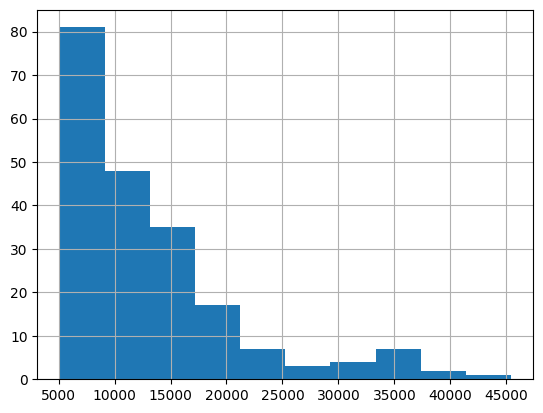

In [252]:
df["price"].hist()

<Axes: >

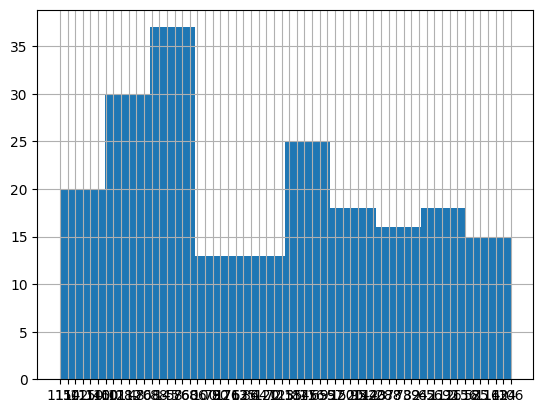

In [253]:
df['horsepower'].hist()

<Axes: >

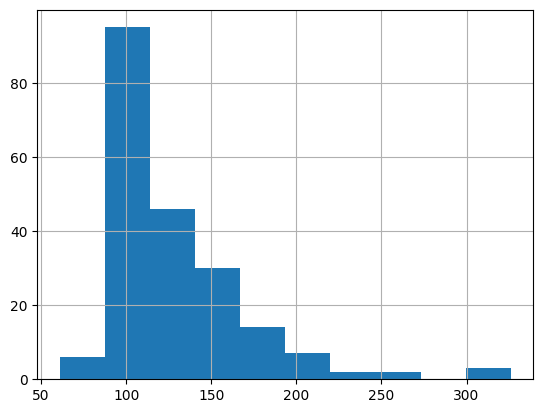

In [254]:
df['engine-size'].hist()

<Axes: >

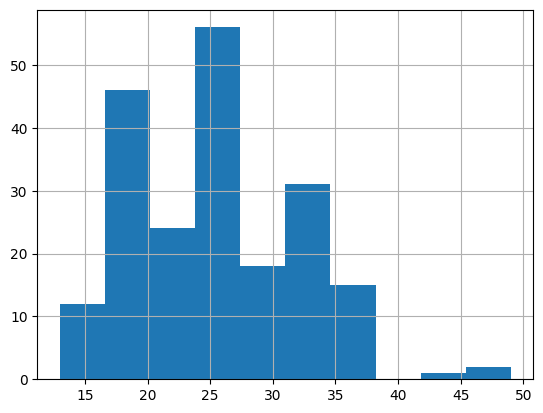

In [255]:
df['city-mpg'].hist()

In [256]:
df.replace("?",np.nan, inplace=True)

In [257]:
df["normalized-losses"] = pd.to_numeric(
    df["normalized-losses"],
    errors="coerce"
)

df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

In [258]:
df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


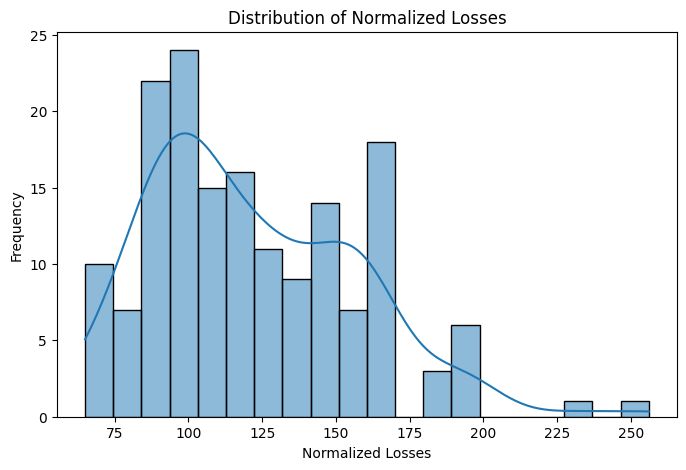

Skewness of Normalized Losses: 0.766


In [259]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='normalized-losses',
    bins=20,
    kde=True
)
plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')
plt.show()
print("Skewness of Normalized Losses:",
      round(df['normalized-losses'].skew(), 3))

In [260]:
df.shape

(205, 15)

In [261]:
df['horsepower'].fillna(
    df['horsepower'].median(),
    inplace=True
)

/tmp/ipykernel_1727/2085030141.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].fillna(


In [262]:
df.duplicated().sum()

np.int64(0)

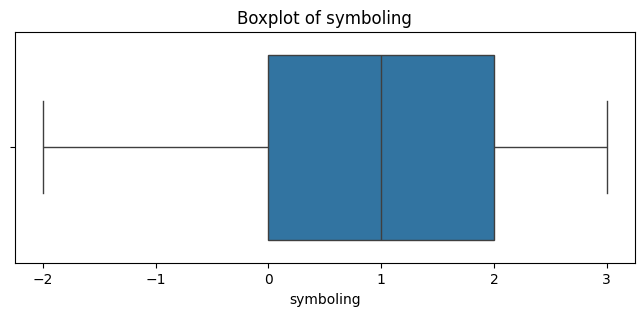

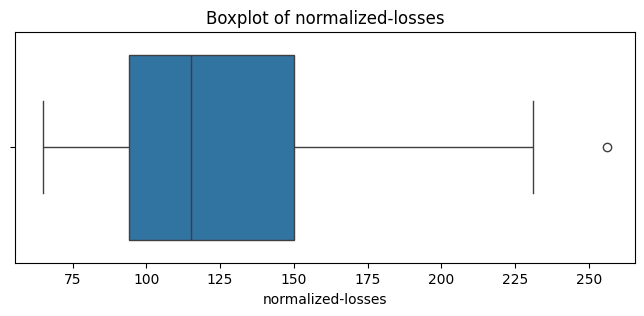

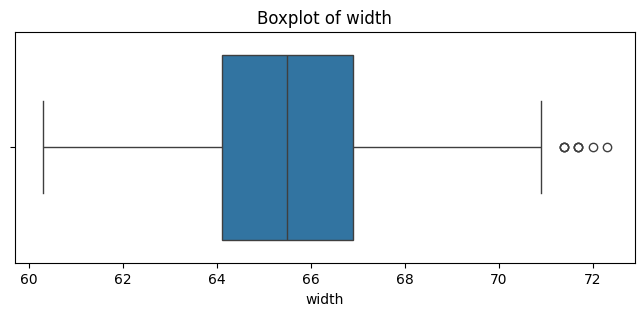

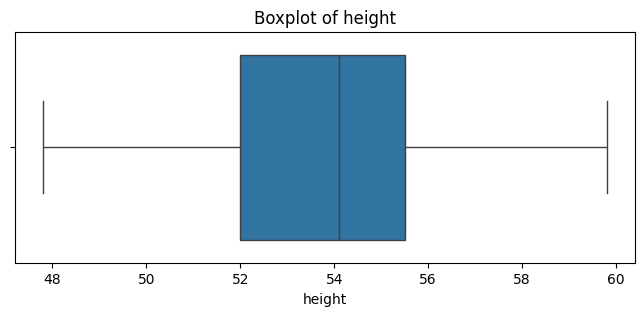

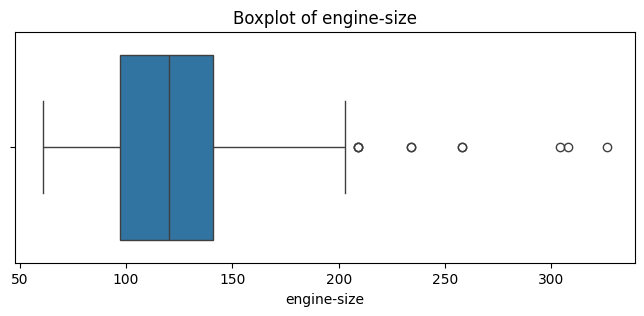

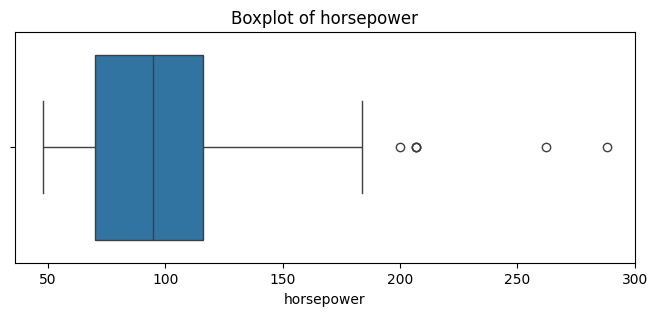

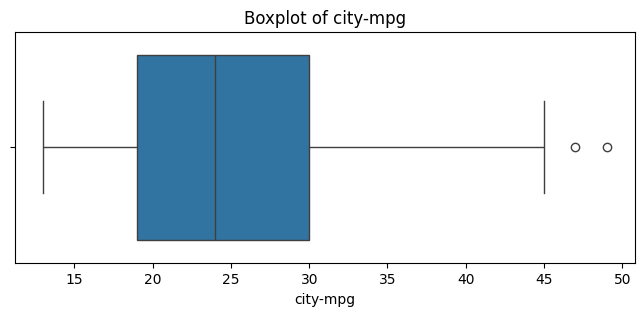

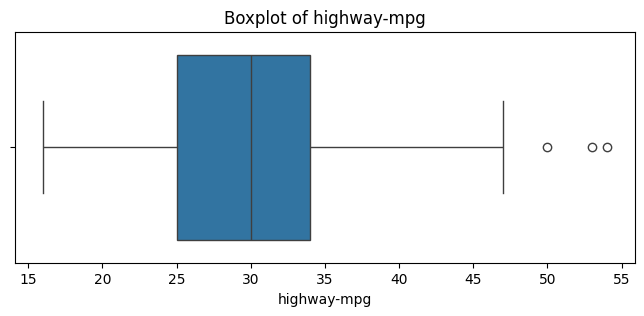

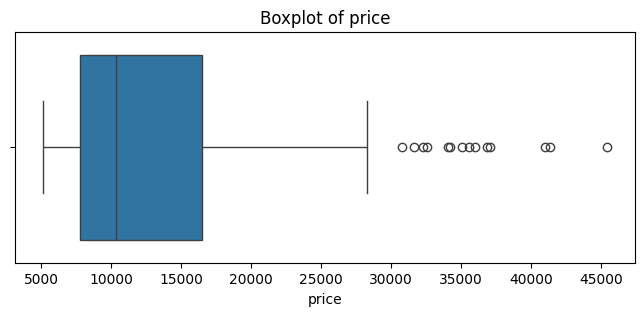

In [263]:
num_cols =df.select_dtypes(include=np.number).columns
for col in num_cols:
  plt.figure(figsize=(8,3))
  sns.boxplot(x=df[col])
  plt.title(f'Boxplot of {col}')
  plt.show()

In [264]:
num_cols =df.select_dtypes(include=np.number).columns
for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 -(1.5 * IQR)
  upper_bound = Q3 +(1.5 * IQR)
  df = df[(df[col]>= lower_bound)&
          (df[col] <= upper_bound)]
print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (127, 15)


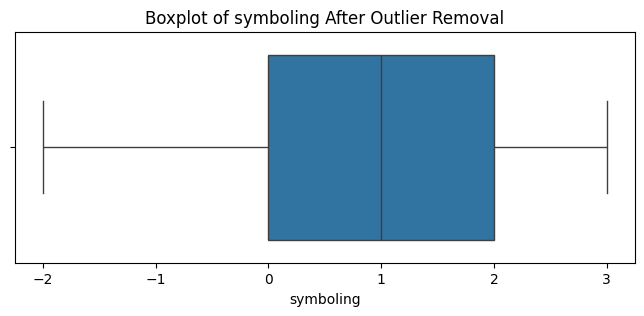

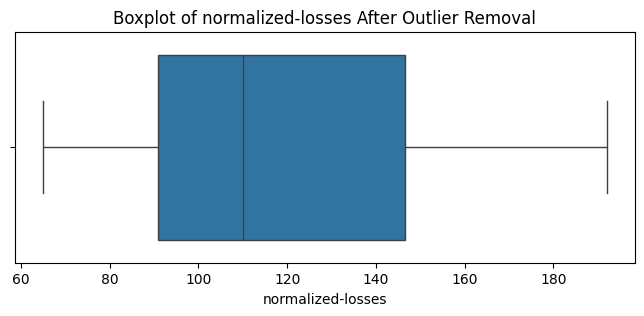

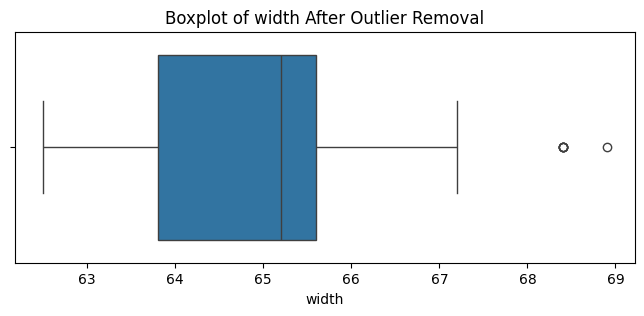

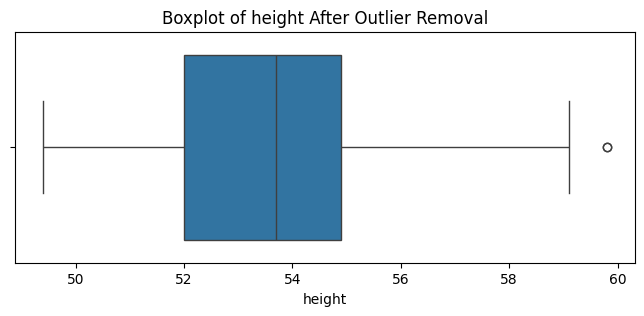

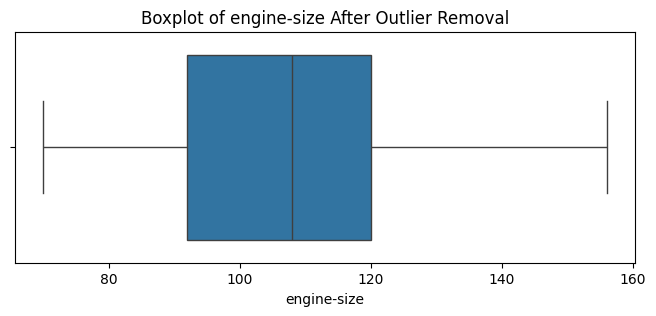

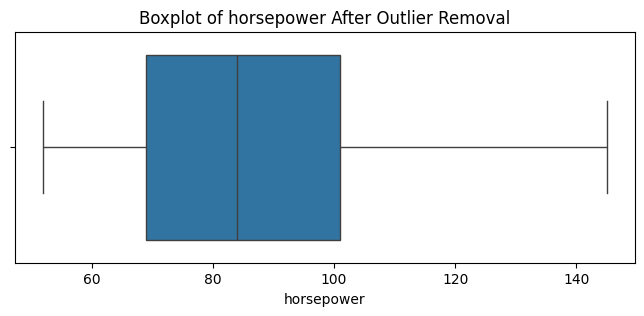

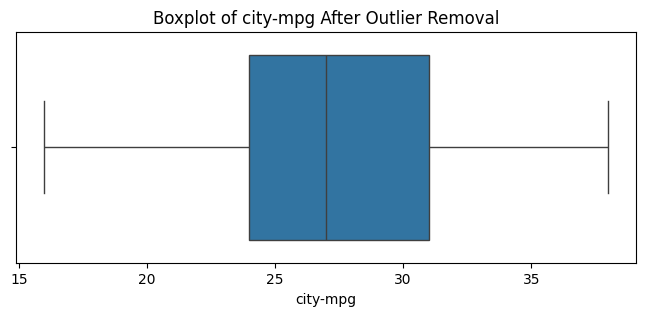

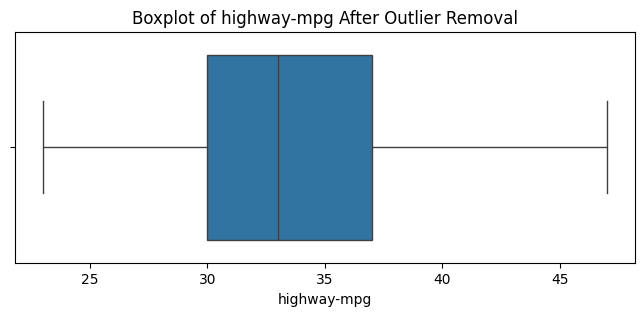

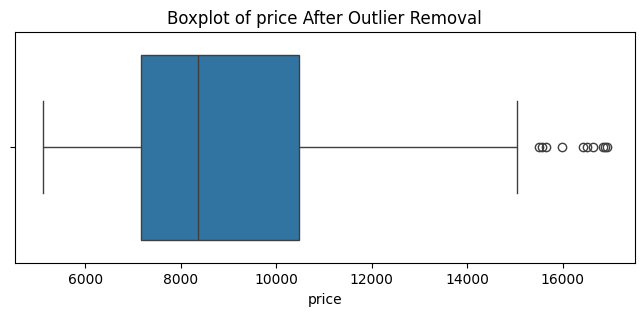

In [265]:
for col in num_cols:

    plt.figure(figsize=(8,3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col} After Outlier Removal')

    plt.show()

In [266]:
df_num=df.select_dtypes(["int64","float64"])
df_cat=df.select_dtypes(object)

In [267]:
df_cat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 127 entries, 3 to 200
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   make             127 non-null    object
 1   fuel-type        127 non-null    object
 2   body-style       127 non-null    object
 3   drive-wheels     127 non-null    object
 4   engine-location  127 non-null    object
 5   engine-type      127 non-null    object
dtypes: object(6)
memory usage: 6.9+ KB


In [268]:
from sklearn.preprocessing import LabelEncoder
for col in df_cat :
    le=LabelEncoder() #create the object of LabelEncoder class
    df_cat[col]=le.fit_transform(df_cat[col])

lab_3

In [269]:
df.corr(numeric_only=True)

,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price
symboling,1.000000,0.483457,-0.201914,-0.445636,-0.260931,0.062235,-0.089114,0.002235,-0.110837
normalized-losses,0.483457,1.000000,0.062257,-0.406003,-0.037066,0.235052,-0.254319,-0.191595,0.216313
width,-0.201914,0.062257,1.000000,0.305671,0.691014,0.575998,-0.543340,-0.532092,0.758245
height,-0.445636,-0.406003,0.305671,1.000000,0.323635,-0.063214,-0.061575,-0.099715,0.277159
engine-size,-0.260931,-0.037066,0.691014,0.323635,1.000000,0.592220,-0.396903,-0.392745,0.550948
horsepower,0.062235,0.235052,0.575998,-0.063214,0.592220,1.000000,-0.808931,-0.792972,0.711622
city-mpg,-0.089114,-0.254319,-0.543340,-0.061575,-0.396903,-0.808931,1.000000,0.959454,-0.694821
highway-mpg,0.002235,-0.191595,-0.532092,-0.099715,-0.392745,-0.792972,0.959454,1.000000,-0.681679
price,-0.110837,0.216313,0.758245,0.277159,0.550948,0.711622,-0.694821,-0.681679,1.000000


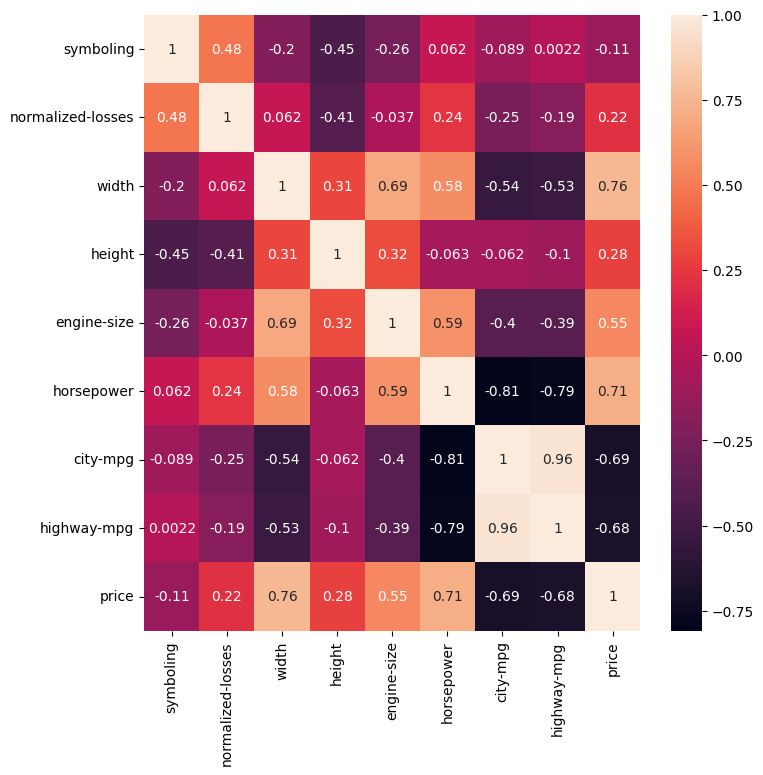

In [270]:
plt.figure(figsize=(8,8))
sns.heatmap(df_num.corr(), annot=True)
plt.show()

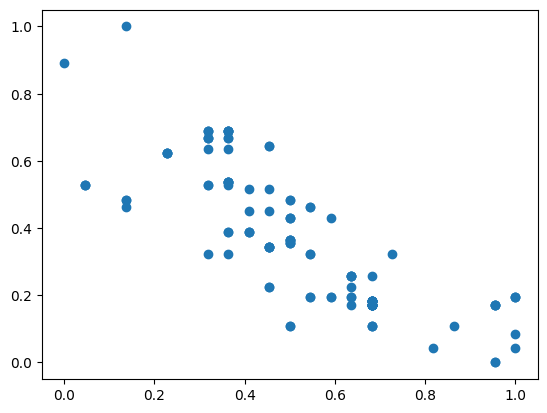

np.float64(0.5128157731843315)

In [271]:
plt.scatter(df_new['city-mpg'],df_new['horsepower'])
plt.show()
df['horsepower'].skew()

In [272]:
df_new=pd.concat([df_num,df_cat],axis=1)

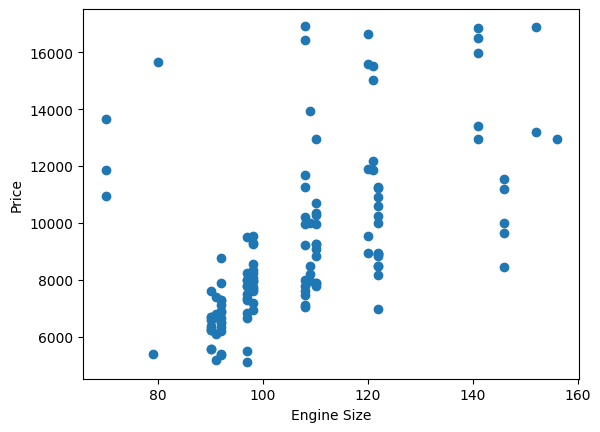

,engine-size
3,109
10,108
11,108
19,90
20,90
...,...
194,141
195,141
196,141
197,141


In [273]:
plt.scatter(df_new['engine-size'], df_num['price'])
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.show()
df['engine-size']

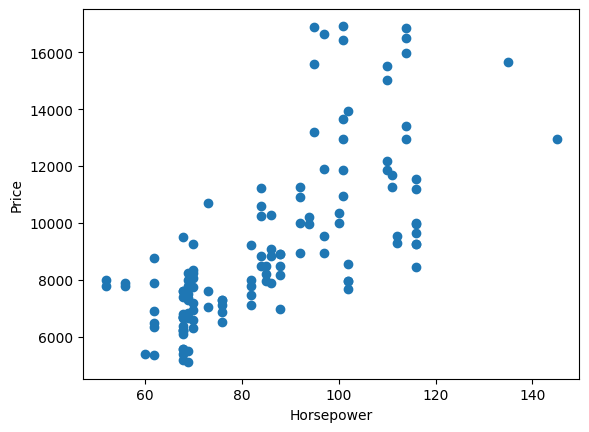

np.float64(0.5128157731843315)

In [274]:
plt.scatter(df_new['horsepower'], df_new['price'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()
df['horsepower'].skew()

<Axes: xlabel='fuel-type', ylabel='price'>

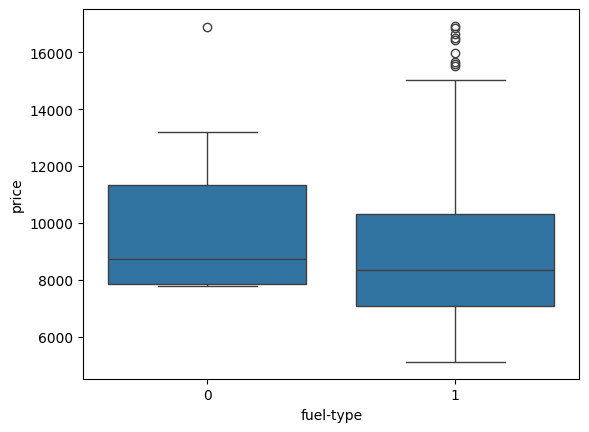

In [275]:
sns.boxplot(x='fuel-type', y='price', data=df_new)

<Axes: xlabel='fuel-type', ylabel='price'>

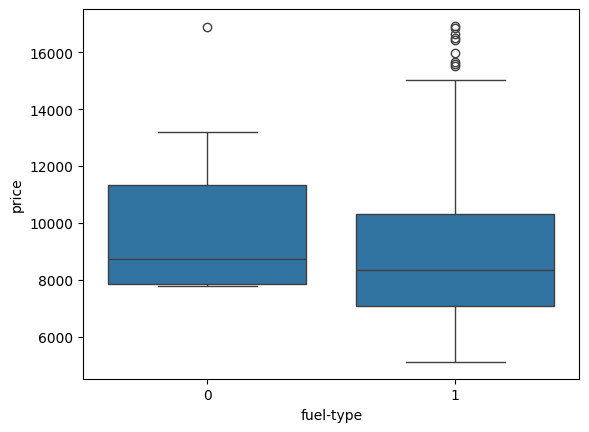

In [276]:
sns.boxplot(x='fuel-type', y='price', data=df_new)

In [277]:
from sklearn.preprocessing import MinMaxScaler

for col in df_new.columns:
    mx = MinMaxScaler()
    df_new[col] = mx.fit_transform(df_new[[col]])

#fit()-> it helps to learn from data provide
# transform () -> for transforming using scalling encoding
# fit_tranfrom () -. for both fit () + transform() -> learn from transformed data



In [278]:
from sklearn.preprocessing import StandardScaler
for col in df_new:
    #create object of StandardScaler
    ss=StandardScaler()
    #call function
    df_new[col]=ss.fit_transform(df_new[[col]]) #[[]] : 2D Array

In [279]:
df_new["area"]=df_new["width"]*df_new["height"]

In [280]:
df_new.head()

,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price,make,fuel-type,body-style,drive-wheels,engine-location,engine-type,area
3,1.074631,1.556596,0.895901,0.282088,0.107198,0.859768,-0.731705,-0.637268,1.620229,-2.209708,0.259281,0.485189,-0.294331,0.0,-0.154243,0.252723
10,1.074631,2.479907,-0.184772,0.282088,0.050941,0.807399,-0.937751,-0.831819,2.469872,-1.939609,0.259281,0.485189,1.782341,0.0,-0.154243,-0.052122
11,-0.733026,2.479907,-0.184772,0.282088,0.050941,0.807399,-0.937751,-0.831819,2.639458,-1.939609,0.259281,0.485189,1.782341,0.0,-0.154243,-0.052122
19,0.170802,-0.619782,-1.111063,-0.708271,-0.961678,-0.816058,2.152933,1.891890,-1.002358,-1.669510,0.259281,-0.915243,-0.294331,0.0,-0.154243,0.786934
20,-0.733026,-1.180364,-1.111063,-0.708271,-0.961678,-0.816058,2.152933,1.891890,-0.906430,-1.669510,0.259281,0.485189,-0.294331,0.0,-0.154243,0.786934
